# 网球逐分序列的 PELT 变点检测

参考 [2024 MCM C](https://www.contest.comap.com/undergraduate/contests/mcm/contests/2024/problems/2024_MCM_Problem_C.pdf)。
用历史模拟比赛拟合含发球方的逻辑回归基线，在一场测试比赛上对逐分残差做离线变点分析。
已知模拟转折位置用于核对结果。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import ruptures as rpt
from scipy.special import expit
from sklearn.linear_model import LogisticRegression

rng = np.random.default_rng(2024)
n_matches, points_per_match = 24, 210
history_serve = rng.integers(0, 2, size=n_matches * points_per_match)
history_edge = np.repeat(rng.normal(0, 0.45, n_matches), points_per_match)
history_x = np.column_stack([history_serve, history_edge])
history_y = rng.binomial(1, expit(-0.65 + 1.3 * history_serve + history_edge))
baseline = LogisticRegression().fit(history_x, history_y)

n = 390
known_breakpoints = [125, 255]
serving = rng.integers(0, 2, size=n)
rank_edge = np.full(n, 0.15)
momentum = np.repeat([-1.0, 1.1, -0.85], [125, 130, 135])
won_point = rng.binomial(1, expit(-0.65 + 1.3 * serving + rank_edge + momentum))
test_x = np.column_stack([serving, rank_edge])
baseline_probability = baseline.predict_proba(test_x)[:, 1]
residual = won_point - baseline_probability

pelt = rpt.Pelt(model="l2", min_size=35, jump=1).fit(residual)
penalties = [1.0, 1.7, 2.4]
detected = {penalty: pelt.predict(pen=penalty)[:-1] for penalty in penalties}
print("Simulated segment boundaries:", known_breakpoints)
print(pd.Series(detected, name="Detected boundaries"))

Simulated segment boundaries: [125, 255]
1.0    [46, 124, 257]
1.7        [124, 257]
2.4        [124, 257]
Name: Detected boundaries, dtype: object


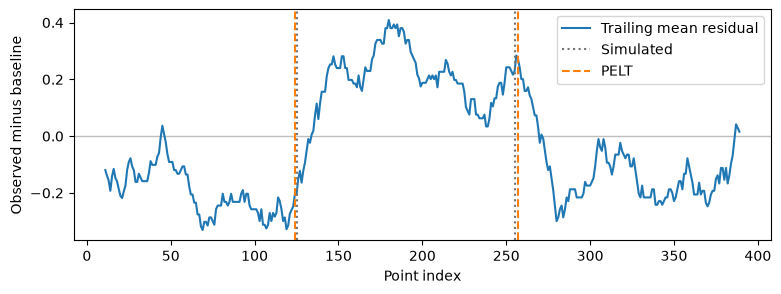

In [2]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.axhline(0, color="0.75", linewidth=1)
ax.plot(pd.Series(residual).rolling(24, min_periods=12).mean(), label="Trailing mean residual")
for i, boundary in enumerate(known_breakpoints):
    ax.axvline(boundary, color="0.45", linestyle=":", label="Simulated" if i == 0 else None)
for i, boundary in enumerate(detected[1.7]):
    ax.axvline(boundary, color="tab:orange", linestyle="--", label="PELT" if i == 0 else None)
ax.set(xlabel="Point index", ylabel="Observed minus baseline")
ax.legend()
plt.show()

罚项影响检测到的变点数，最短分段长度对应希望识别的变化尺度。
实战中按整场比赛划分训练和验证。要检验势头是否超出随机波动，可以从发球基线模拟整场，
对模拟序列重复同一检测流程。离线检测使用完整区间，实时预警应在每个时点截断可用数据。